# Assembly laboratory

This notebook reads the trajectories' derived tables. It does **not** rerun HOOMD. Its purpose is to connect the theoretical observables to the numbers produced by the experiment.

Read `docs/theory/` before using it.

## 1. Locate the project and load the five conditions

Each condition contains a fully resolved configuration, a GSD trajectory, a time-series CSV, and a summary JSON. Here we read only the last two.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'assembly.toml').exists():
            return candidate
    raise FileNotFoundError('Could not find assembly.toml above the notebook working directory.')

ROOT = find_project_root(Path.cwd().resolve())
OUTPUT = ROOT / 'outputs' / 'assembly'
CONDITIONS = [
    'isotropic',
    'three-patch',
    'three-patch--delayed-field',
    'three-patch--small',
    'three-patch--large',
]

missing = [
    condition
    for condition in CONDITIONS
    if not (OUTPUT / condition / 'seed-0041' / 'observables.csv').exists()
]
if missing:
    raise FileNotFoundError(
        f'Missing full-study outputs for {missing}. Run: pixi run assembly-study'
    )

series = {
    condition: pd.read_csv(OUTPUT / condition / 'seed-0041' / 'observables.csv')
    for condition in CONDITIONS
}
summaries = {
    condition: json.loads(
        (OUTPUT / condition / 'seed-0041' / 'summary.json').read_text()
    )
    for condition in CONDITIONS
}

ROOT

PosixPath('/Users/lucasmasiero/Documents/Cohesia/Repositories/research/storage/projects/code/local/patchy-particle-emergence/hoomd')

## 2. Compare final observations

The largest component measures connectivity, mean degree measures local contact count, and the two $\Psi_6$ values separate local angular compatibility from sample-wide agreement.

In [2]:
columns = {
    'final_largest_component_fraction': 'largest component',
    'final_mean_degree': 'mean degree',
    'final_local_bond_order_6': 'local psi6',
    'final_global_bond_order_6': 'global psi6',
    'final_coordination_3_fraction': 'degree-3 fraction',
    'final_coordination_6_fraction': 'degree-6 fraction',
}
comparison = pd.DataFrame.from_dict(summaries, orient='index')[list(columns)]
comparison = comparison.rename(columns=columns)
comparison.round(3)

,largest component,mean degree,local psi6,global psi6,degree-3 fraction,degree-6 fraction
isotropic,0.729,4.542,0.946,0.714,0.250,0.375
three-patch,0.833,2.396,0.930,0.234,0.531,0.000
three-patch--delayed-field,0.896,2.146,0.954,0.837,0.385,0.000
three-patch--small,0.979,2.333,0.953,0.906,0.521,0.000
three-patch--large,0.682,2.365,0.929,0.224,0.469,0.000


Ask three separate questions of the table:

1. Did one connected structure form?
2. Was it compact or open?
3. Did local angular order agree across the complete sample?

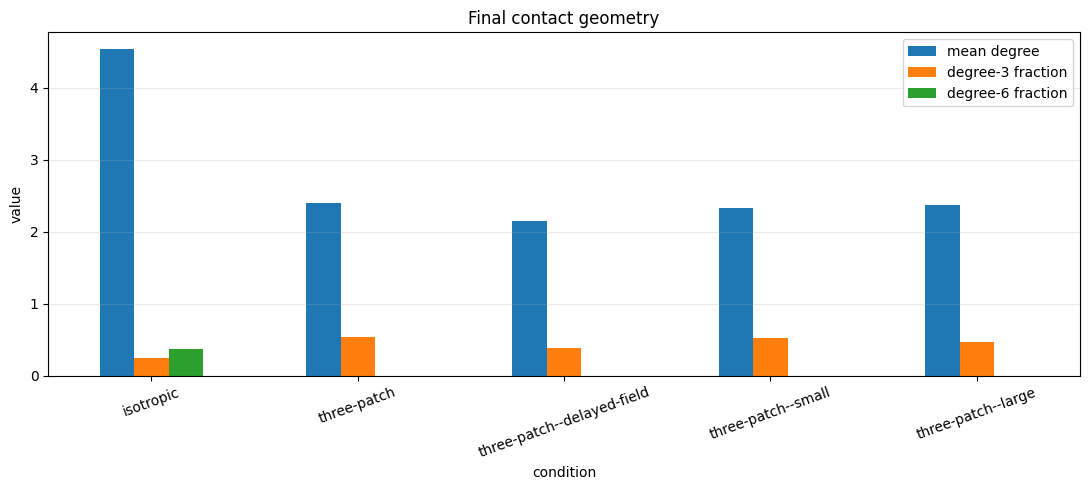

In [3]:
ax = comparison[['mean degree', 'degree-3 fraction', 'degree-6 fraction']].plot.bar(
    figsize=(11, 5),
    rot=20,
)
ax.set(title='Final contact geometry', xlabel='condition', ylabel='value')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

## 3. Connectivity through time

A final frame hides formation and breakage. Plotting $S_{\max}(t)$ shows when a large structure first appears and whether it persists.

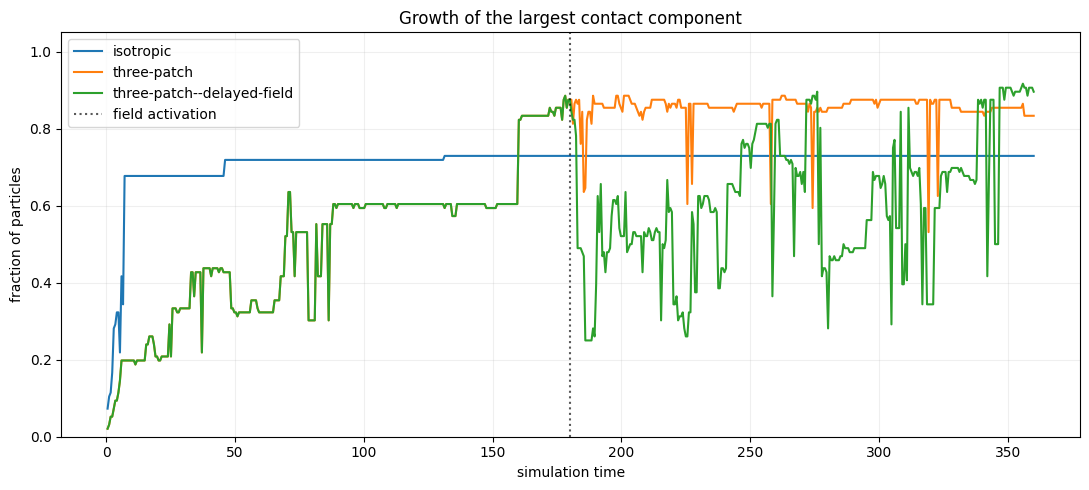

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
for condition in ('isotropic', 'three-patch', 'three-patch--delayed-field'):
    frame = series[condition]
    ax.plot(frame['time'], frame['largest_component_fraction'], label=condition)
ax.axvline(180, color='black', linestyle=':', alpha=0.65, label='field activation')
ax.set(
    title='Growth of the largest contact component',
    xlabel='simulation time',
    ylabel='fraction of particles',
    ylim=(0, 1.05),
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()

## 4. Local versus global order

Local order can be high in several differently rotated domains. Global order becomes high only when their complex phases agree. The field starts at $t=180$; compare the values immediately before and after that intervention.

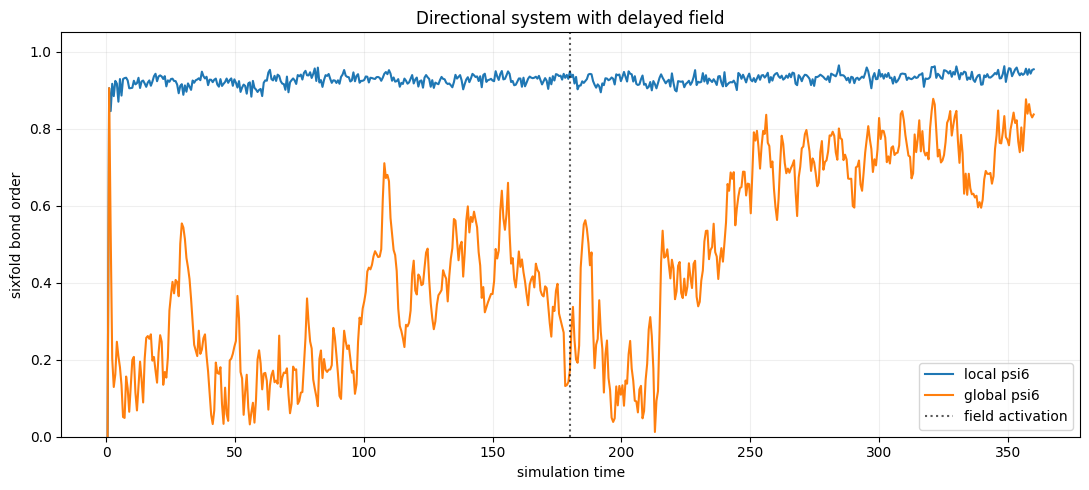

In [6]:
field = series['three-patch--delayed-field']
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(field['time'], field['local_bond_order_6'], label='local psi6')
ax.plot(field['time'], field['global_bond_order_6'], label='global psi6')
ax.axvline(180, color='black', linestyle=':', alpha=0.65, label='field activation')
ax.set(
    title='Directional system with delayed field',
    xlabel='simulation time',
    ylabel='sixfold bond order',
    ylim=(0, 1.05),
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()

## 5. Your first extension

Do not tune until a picture looks attractive. Write a hypothesis first. A good first exercise is: *Does delaying the field increase the amount of locally assembled structure available to be reorganized, while making global alignment slower?*

Create new field-start conditions in `assembly.toml`, run multiple seeds, and compare distributions of first-passage time rather than only one final value.